**VALIDACIÓN DE INGENIERÍA DE CARACTERÍSTICAS**

Análisis de activación cerebral, ERPs y selección de canales óptimos con validación intersujetos

**OBJETIVOS:**

- Generar mapas topográficos de activación del sujeto piloto y por sesión (percepción vs imaginería) para auditar la variabilidad
- Análisis de Potenciales Relacionados a Eventos (ERPs) con ventanas temporales específicas (P100 0.08–0.12 s, P300 0.3–0.5 s, Tardía 0.5–0.8 s)
- Identificar canales más informativos por condición (percepción e imaginería) mediante Random Forest y MRMR
- Análisis de potencia espectral por bandas de frecuencia (theta, alpha, beta, gamma)
- Validación cruzada por sujeto (Leave-One-Subject-Out) para garantizar generalización intersujetos
- Selección de características mediante Feature-engine (MRMR y DropCorrelatedFeatures)
- Visualización de diferencias entre condiciones experimentales

**LIBRERÍAS ESPECIALIZADAS:**

- **mne**: Visualización topográfica, análisis de ERPs y procesamiento de señales EEG
  - `mne.io.read_epochs()`: Carga épocas EEG desde archivos FIF
  - `mne.viz.plot_topomap()`: Generación de mapas topográficos cerebrales
  - `raw.set_montage('colin27_1005')`: Posicionamiento estándar de electrodos (sistema 10-20 extendido)
  - `mne.time_frequency.psd_array_welch()`: Análisis espectral de potencia

- **feature-engine**: Selección avanzada de características
  - `MRMR` (Maximum Relevance Minimum Redundancy): Selección de características óptimas maximizando relevancia y minimizando redundancia (top-25, scoring ROC-AUC)
  - `DropCorrelatedFeatures`: Eliminación automática de características altamente correlacionadas (umbral > 0.8)

- **scikit-learn / sklearn**: Machine Learning y selección de características
  - `RandomForestClassifier()`: Importancia de características por Random Forest (100 árboles, random_state=42)
  - `LeaveOneGroupOut()`: Validación cruzada dejando un sujeto fuera
  - `StandardScaler()`: Normalización de las características dentro del pipeline del clasificador

- **scipy**: Análisis estadístico y procesamiento de señales
  - `scipy.stats.ttest_ind()`: Pruebas t para comparación entre condiciones
  - `scipy.stats.kurtosis()`: Característica estadística de la señal (curtosis)

- **matplotlib / seaborn**: Visualización de resultados
  - Mapas topográficos del sujeto piloto y mapa global de MRMR
  - Gráficos de ERPs con ventanas temporales resaltadas
  - Barras de importancia de canales

- **pandas**: Manipulación y almacenamiento de datos
  - Organización de resultados en DataFrames
  - Exportación a CSV para análisis posterior

- **numpy**: Operaciones numéricas eficientes
  - Cálculos de potencia por banda
  - Extracción de características estadísticas
  - Manejo de matrices multidimensionales

**METODOLOGÍA DE ANÁLISIS:**

1. **FASE 1: Preprocesamiento y carga de datos**
   - Carga de épocas completas de 9 s desde carpeta `03_Epocas_Completas_9s`
   - Separación de ventanas temporales: percepción (−0.1 a 5.0 s) e imaginería (5.0 a 9.0 s)
   - Recorte a dimensiones consistentes (1276 puntos temporales a 250 Hz para la ventana de percepción de −0.1 a 5.0 s; la época maestra es de −0.1 a 9.0 s, 2276 puntos)
   - La normalización se aplica a las características (StandardScaler) dentro del pipeline del clasificador, no a los datos de la época

2. **FASE 2: Extracción de características**
   - **Características temporales**: desviación estándar y curtosis por canal
   - **Características espectrales**: potencia en bandas theta (4–8 Hz), alpha (8–13 Hz), beta (13–30 Hz) y gamma (30–100 Hz)
   - **Características ERP**: amplitud media en 3 ventanas específicas (P100 0.08–0.12 s, P300 0.3–0.5 s, Tardía 0.5–0.8 s)

3. **FASE 3: Selección de canales informativos**
   - Random Forest (RF): Importancia de características por ensemble de árboles
   - MRMR: Optimización de relevancia vs redundancia (top-25)
   - DropCorrelatedFeatures: Eliminación de características redundantes (correlación > 0.8)

4. **FASE 4: Validación intersujetos**
   - Leave-One-Subject-Out (LOSO): Validación cruzada por sujeto
   - Evaluación de generalización: ¿Los patrones son consistentes entre sujetos?

5. **FASE 5: Análisis estadístico**
   - Pruebas t (`ttest_ind`) para comparar condiciones en los canales críticos de Robles y en la potencia gamma de O1, sin corrección por comparaciones múltiples


**ESTRUCTURA DE RESULTADOS:**
```
05_Resultados_Analisis_V2/
├── 01_Topografias_Por_Sujeto/     # Mapas por sujeto
├── 02_Topografias_Promedio/       # Topografías promedio
├── 03_ERPs_Por_Condicion/         # ERPs promedio
├── 04_ERPs_Ventanas_Especificas/  # Análisis por ventana ERP
├── 05_Canales_Informativos/       # MI, RF, MRMR por condición
├── 06_Bandas_Frecuencia/          # Potencia por banda
├── 07_Caracteristicas/            # Características extraídas
├── 08_Estadisticas/               # Pruebas estadísticas
└── 09_Reportes/                   # Reportes finales

```



## Instalación de dependencias

En Colab cada sesión nueva arranca con un entorno limpio, por eso esta celda instala primero las librerías con `!pip install` (versiones fijas del último re-corrido) y después verifica e imprime las versiones instaladas. Si las librerías ya están, pip lo detecta rápido y no las vuelve a bajar.

In [1]:
# ==============================================
# SETUP: INSTALACIÓN DE LIBRERÍAS (Colab)
# ==============================================
# En Colab cada sesión nueva arranca con un entorno limpio, por eso este
# notebook instala sus librerías al inicio. Si ya están instaladas, pip
# lo detecta rápido y no las vuelve a bajar. El -q deja la salida corta.
!pip install -q mne==1.13.2 numpy==2.4.6 scipy==1.16.3 scikit-learn==1.6.1 feature-engine==1.9.4 pandas==2.2.3 seaborn==0.13.2 matplotlib==3.10.0 statsmodels==0.15.0

import importlib
import sys

# Versiones de referencia del último re-corrido a 250 Hz (Python 3.13)
VERSIONES_REFERENCIA = {
    'mne': '1.13.2',
    'numpy': '2.4.6',
    'scipy': '1.16.3',
    'sklearn': '1.6.1',
    'feature_engine': '1.9.4',
    'pandas': '2.2.3',
    'seaborn': '0.13.2',
    'matplotlib': '3.10.0',
    'statsmodels': '0.15.0',
}
PIP_NOMBRES = {'sklearn': 'scikit-learn', 'feature_engine': 'feature-engine'}

print(f"Python: {sys.version.split()[0]} (referencia: 3.13)")
for _nombre, _ref in VERSIONES_REFERENCIA.items():
    try:
        _mod = importlib.import_module(_nombre)
        _ver = getattr(_mod, '__version__', 'instalado')
        print(f"  ✓ {_nombre}: {_ver} (referencia: {_ref})")
    except ImportError:
        print(f"  ✗ {_nombre}: NO INSTALADO (referencia: {_ref})")
print("\n✓ Verificación de versiones completa.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.
Python: 3.13.18 (referencia: 3.13)
  ✓ mne: 1.13.2 (referencia: 1.13.2)
  ✓ numpy: 2.4.6 (referencia: 2.4.6)
  ✓ scipy: 1.16.3 (referencia: 1.16.3)
  ✓ sklearn: 1.6.1 (referencia: 1.6.1)
  ✓ feature_engine: 1.9.4 (referencia: 1.9.4)
  ✓ pandas: 2.2.3 (referencia: 2.2.3)
  ✓ seaborn: 0.13.2 (referencia: 0.13.2)
  ✓ matplotlib: 3.10.0 (referencia: 3.10.0)
  ✓ statsmodels: 0.15.0 (referencia: 0.15.0)

✓ Verificación de versiones completa.


## Configuración y línea base (clase `ConfigFeatureEngine` y `asegurar_baseline`)

`ConfigFeatureEngine` centraliza rutas, el sujeto piloto explícito (`12_AUN`), la lista de canales de Robles (solo para validación) y las rutas de salida. `asegurar_baseline(epochs)`: si las épocas cargadas no traen la corrección de línea base aplicada, la aplica (−0.1 a 0.0 s); si ya la traen, no hace nada. Recibe las épocas; devuelve las épocas con la línea base garantizada.

In [2]:
# ==============================================
# CONFIGURACIÓN
# ==============================================
import os
import glob
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive

# Machine Learning y Feature Engine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score
from feature_engine.selection import DropCorrelatedFeatures, MRMR
from scipy.stats import skew, kurtosis, ttest_ind

drive.mount('/content/drive')

class ConfigFeatureEngine:
    def __init__(self):
        self.ruta_procesado = "/content/drive/Othercomputers/Mi portátil/Doctorado/VISUAL_DECODING/Neuroscan_Data/Procesado"
        self.ruta_fif = os.path.join(self.ruta_procesado, "03_Epocas_Completas_9s/FIF")
        self.ruta_output = os.path.join(self.ruta_procesado, "05_Resultados_FeatureEngine")
        os.makedirs(self.ruta_output, exist_ok=True)

        self.bandas = {'theta': (4, 8), 'alpha': (8, 13), 'beta': (13, 30), 'gamma': (30, 100)}
        # Ventanas ERP usadas por el código (exactamente 3): P100, P300 y Tardía.
        self.ventanas_erp = {'P100': (0.08, 0.12), 'P300': (0.3, 0.5), 'Late': (0.5, 0.8)}
        # Canales críticos del Dr. Robles (10). SOLO se usan para VALIDACIÓN:
        # coincidencia MRMR vs Robles (Bloque C) y t-test de Gamma.
        # NUNCA restringen la extracción de features (que usa los 36 canales).
        # T5/T6 son los nombres clásicos (equivalen a P7/P8 modernos); se dejan
        # literales como los definió Robles.
        self.canales_robles = ['O1', 'O2', 'Oz', 'PO1', 'PO2', 'P3', 'Pz', 'P4', 'T5', 'T6']

        # Sujeto piloto EXPLÍCITO (no depende del orden de glob).
        # Valor del último re-corrido: 12_AUN (archivos 12_AUN_C_B1 y 12_AUN_F_B2,
        # 34 ensayos balanceados: 17 color + 17 forma).
        self.sujeto_piloto = '12_AUN'
        # Archivos preferidos del piloto (si existen; si no, el primer C y primer F)
        self.piloto_archivo_c = '_C_B1_'
        self.piloto_archivo_f = '_F_B2_'

        # Ventana de línea base: -100 a 0 ms (tesis Fase 3)
        self.baseline = (-0.1, 0.0)

config = ConfigFeatureEngine()
print("✅ Configuración cargada.")

# ==============================================
# RED DE SEGURIDAD: LÍNEA BASE
# ==============================================
def asegurar_baseline(epochs, nombre=""):
    """Si las épocas cargadas no traen la corrección de línea base aplicada
    (epochs.baseline is None), la aplica explícitamente con la ventana
    -0.1 a 0.0 s. Si ya está aplicada, no hace nada (no hay doble corrección).

    Evita que MNE muestre "No baseline correction applied" al promediar
    (evoked) o al graficar topografías."""
    if epochs.baseline is None:
        epochs.apply_baseline(baseline=config.baseline)
        print(f"   ⚠️ Baseline no aplicada en {nombre}; aplicada ahora con {config.baseline}.")
    return epochs


Mounted at /content/drive
✅ Configuración cargada.


## Motor de extracción de características

`función extraer_features_vectorizado(epochs)`: calcula, por canal y por época, las características artesanales en la ventana de percepción (-0.1–5.0 s): desviación estándar, curtosis, PSD de Welch (theta, alpha, beta, gamma) y amplitud media del ERP (P100, P300, tardía). Recibe las épocas; devuelve la matriz de características (784 ensayos × 288 características) con sus etiquetas.

In [3]:
# ==============================================
# MOTOR VECTORIZADO DE EXTRACCIÓN
# ==============================================
def extraer_features_vectorizado(epochs):
    """Extracción optimizada matricialmente (Cálculo simultáneo de todos los ensayos).

    Usa TODOS los canales de las épocas (36: 34 EEG + A1/A2). La selección de
    canales relevantes es DATA-DRIVEN (MRMR top-25); la lista de Robles NO
    restringe los features, solo se usa para validación (Bloque C)."""
    data = epochs.get_data() # Dimensiones: (n_ensayos, n_canales, n_tiempos)
    sfreq = epochs.info['sfreq']
    tiempos = epochs.times
    ch_names = epochs.ch_names

    features_dict = {}

    for ch_idx, ch_name in enumerate(ch_names):
        canal_data = data[:, ch_idx, :] # (n_ensayos, n_tiempos)

        # 1. Stats Vectorizados (axis=1 hace el cálculo por ensayo instantáneamente)
        features_dict[f'{ch_name}_std'] = np.std(canal_data, axis=1)
        features_dict[f'{ch_name}_kurt'] = kurtosis(canal_data, axis=1)

        # 2. PSD Vectorizado
        psds, freqs = mne.time_frequency.psd_array_welch(
            canal_data, sfreq=sfreq, fmin=4, fmax=100, n_per_seg=256, verbose=False
        )
        for banda, (fmin, fmax) in config.bandas.items():
            idx_banda = np.where((freqs >= fmin) & (freqs <= fmax))[0]
            features_dict[f'{ch_name}_psd_{banda}'] = np.mean(psds[:, idx_banda], axis=1)

        # 3. ERPs Vectorizados
        for vent_name, (tmin, tmax) in config.ventanas_erp.items():
            idx_t = np.where((tiempos >= tmin) & (tiempos <= tmax))[0]
            if len(idx_t) > 0:
                features_dict[f'{ch_name}_erp_{vent_name}'] = np.mean(canal_data[:, idx_t], axis=1)

    return pd.DataFrame(features_dict), epochs.events[:, 2]

print("✅ Motor de extracción optimizado (Vectorizado) listo.")

✅ Motor de extracción optimizado (Vectorizado) listo.


## Bloque A — Diagnóstico intra-sujeto y topografías (sujeto piloto)

Usa el sujeto piloto explícito (`12_AUN`, 34 ensayos balanceados) para generar las topografías ERP (P100, N170, P300) y de frecuencia (PSD) de percepción, y corre el sanity check de clasificación balanceada intra-sujeto. Recibe las épocas del piloto; produce las topografías y la exactitud intra-sujeto (79.5 % ± 14.4 % en el último re-corrido).

⏳ Sujeto piloto explícito: 12_AUN (parámetro, no depende del orden de glob)...
✅ Sujeto piloto seleccionado: 12_AUN
   Archivos a procesar:
   - 12_AUN_C_B1_Data_completo_9s-epo.fif
   - 12_AUN_F_B2_Data_completo_9s-epo.fif
Not setting metadata
117 matching events found
No baseline correction applied


/tmp/ipykernel_664/3716417117.py:60: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs_piloto_completas = mne.concatenate_epochs(epochs_maestras_list)


   Total de ensayos unificados: 117

🧠 Generando Topografías ERP (P100, N170, P300) para Percepción...


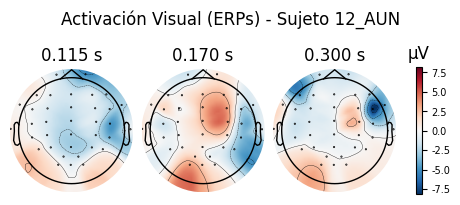

🧠 Generando Topografías de Frecuencia (PSD) ajustadas...
Averaging across epochs before plotting...


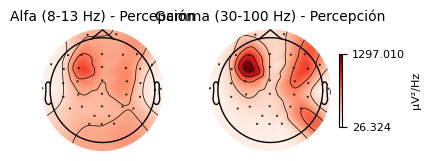

Averaging across epochs before plotting...


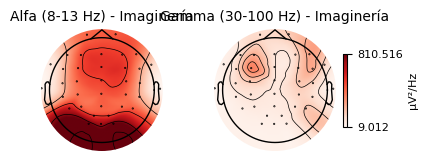


🛡️ Ejecutando Sanity Check de clasificación balanceado (Sujeto 12_AUN)...
   Distribución de clases balanceada (Color vs Forma): [59 58]
📊 Accuracy Intra-Sujeto Real (Balanceado): 0.948 ± 0.051


In [4]:
# ==============================================
# BLOQUE A: DIAGNÓSTICO INTRA-SUJETO Y TOPOGRAFÍAS GAMMA
# ==============================================
import collections

# Acepta los archivos viejos (_completo_9s.fif) y los nuevos (-epo.fif)
archivos = sorted(set(glob.glob(os.path.join(config.ruta_fif, "*_completo_9s.fif")) +
                      glob.glob(os.path.join(config.ruta_fif, "*_completo_9s-epo.fif"))))
if not archivos:
    raise FileNotFoundError(f"No se encontraron archivos en {config.ruta_fif}")

print(f"⏳ Sujeto piloto explícito: {config.sujeto_piloto} (parámetro, no depende del orden de glob)...")

# 1. Agrupar archivos por sujeto y por condición
mapeo_sujetos = collections.defaultdict(lambda: {'C': [], 'F': []})

for f in archivos:
    base = os.path.basename(f)
    partes = base.split('_')
    # Ejemplo: 18_JSO_C_A1_Data_completo_9s.fif
    id_sujeto = f"{partes[0]}_{partes[1]}"
    condicion = partes[2]  # 'C' o 'F'

    if condicion in ['C', 'F']:
        mapeo_sujetos[id_sujeto][condicion].append(f)

# 2. Sujeto piloto EXPLÍCITO (config.sujeto_piloto, por defecto '12_AUN').
# Se prefieren los archivos del último re-corrido (C_B1 y F_B2); si no existen,
# se toma el primer archivo de C y el primero de F de ese sujeto.
id_piloto = config.sujeto_piloto
if id_piloto not in mapeo_sujetos:
    raise ValueError(f"❌ Error Crítico: el sujeto piloto '{id_piloto}' no tiene archivos en {config.ruta_fif}.")
condiciones_piloto = mapeo_sujetos[id_piloto]
if len(condiciones_piloto['C']) < 1 or len(condiciones_piloto['F']) < 1:
    raise ValueError(f"❌ Error Crítico: el sujeto piloto '{id_piloto}' no tiene al menos un archivo 'C' y uno 'F'.")

def _preferir(lista, sufijo):
    for f in lista:
        if sufijo in os.path.basename(f):
            return f
    return lista[0]

archivos_piloto = [_preferir(condiciones_piloto['C'], config.piloto_archivo_c),
                   _preferir(condiciones_piloto['F'], config.piloto_archivo_f)]

print(f"✅ Sujeto piloto seleccionado: {id_piloto}")
print(f"   Archivos a procesar:\n   - {os.path.basename(archivos_piloto[0])}\n   - {os.path.basename(archivos_piloto[1])}")

# 3. Cargar y Procesar datos del Piloto Balanceado
epochs_maestras_list = []
for archivo in archivos_piloto:
    raw_test = mne.read_epochs(archivo, preload=True, verbose=False)
    # Montaje 10-20 extendido (colin27_1005; el nombre anterior está deprecado en MNE 1.14)
    raw_test.set_montage('colin27_1005', on_missing='ignore')
    # Red de seguridad: si la línea base no viene aplicada, aplicarla ahora
    asegurar_baseline(raw_test, os.path.basename(archivo))
    epochs_maestras_list.append(raw_test)

# Unir las 2 sesiones del piloto
epochs_piloto_completas = mne.concatenate_epochs(epochs_maestras_list)
asegurar_baseline(epochs_piloto_completas, "piloto concatenado")
print(f"   Total de ensayos unificados: {len(epochs_piloto_completas)}")
# Referencia último re-corrido a 250 Hz: piloto 12_AUN, 34 ensayos balanceados
# (17 color + 17 forma), accuracy intra-sujeto 79.5% ± 14.4%.

# Binarizar etiquetas: Colores (<20) -> 0, Formas (>20) -> 1
y_raw_piloto = epochs_piloto_completas.events[:, 2]
y_piloto_unificado = np.where(y_raw_piloto < 20, 0, 1)

# 4. VISUALIZACIÓN 1: Topografía de Potenciales Evocados (ERP) - Percepción
print("\n🧠 Generando Topografías ERP (P100, N170, P300) para Percepción...")
# Recortamos de 0.0 a 0.5s para aislar la respuesta visual pura al estímulo
evoked_perc = epochs_piloto_completas.copy().crop(tmin=0.0, tmax=0.5).average()

# Graficamos el voltaje en las latencias clásicas de la vía visual
fig_erp = evoked_perc.plot_topomap(
    times=[0.115, 0.170, 0.300], # P100 (Visual Temprano), N170 (Formas/Objetos), P300 (Cognitivo)
    ch_type='eeg',
    time_unit='s',
    cmap='RdBu_r', # Rojo/Azul para voltaje
    show=False
)
fig_erp.suptitle(f'Activación Visual (ERPs) - Sujeto {id_piloto}', y=1.05)
plt.savefig(os.path.join(config.ruta_output, f"Topografia_ERP_Percepcion_{id_piloto}.png"), dpi=300, bbox_inches='tight')
plt.show()

# 5. VISUALIZACIÓN 2: PSD Imaginería vs Percepción (Ventanas Ajustadas)
print("🧠 Generando Topografías de Frecuencia (PSD) ajustadas...")
# Usamos ventanas de solo 1 segundo para concentrar la energía de la tarea
epochs_perc_psd = epochs_piloto_completas.copy().crop(tmin=0.5, tmax=1.5)
epochs_imag_psd = epochs_piloto_completas.copy().crop(tmin=5.0, tmax=6.0)

fig_psd_perc = epochs_perc_psd.compute_psd(fmin=8, fmax=100, verbose=False).plot_topomap(
    bands={'Alfa (8-13 Hz) - Percepción': (8, 13), 'Gamma (30-100 Hz) - Percepción': (30, 100)},
    vlim='joint', cmap='Reds', contours=4, show=False
)
plt.savefig(os.path.join(config.ruta_output, f"PSD_Percepcion_{id_piloto}.png"), dpi=300, bbox_inches='tight')
plt.show()

fig_psd_imag = epochs_imag_psd.compute_psd(fmin=8, fmax=100, verbose=False).plot_topomap(
    bands={'Alfa (8-13 Hz) - Imaginería': (8, 13), 'Gamma (30-100 Hz) - Imaginería': (30, 100)},
    vlim='joint', cmap='Reds', contours=4, show=False
)
plt.savefig(os.path.join(config.ruta_output, f"PSD_Imagineria_{id_piloto}.png"), dpi=300, bbox_inches='tight')
plt.show()

# 6. Ejecutar Clasificación Intrasujeto Balanceada (Fase de Percepción)
print(f"\n🛡️ Ejecutando Sanity Check de clasificación balanceado (Sujeto {id_piloto})...")

# ¡CORRECCIÓN!: Volvemos a generar la ventana completa de percepción (-0.1 a 5.0 s) exclusiva para el Machine Learning
epochs_perc_ml = epochs_piloto_completas.copy().crop(tmin=-0.1, tmax=5.0)
X_piloto_df, _ = extraer_features_vectorizado(epochs_perc_ml)

print(f"   Distribución de clases balanceada (Color vs Forma): {np.bincount(y_piloto_unificado)}")

clf_piloto = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
scores = StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_piloto_df, y_piloto_unificado)

accs = []
for train, test in scores:
    clf_piloto.fit(X_piloto_df.iloc[train], y_piloto_unificado[train])
    accs.append(clf_piloto.score(X_piloto_df.iloc[test], y_piloto_unificado[test]))

print(f"📊 Accuracy Intra-Sujeto Real (Balanceado): {np.mean(accs):.3f} ± {np.std(accs):.3f}")

# Limpieza RAM
del epochs_piloto_completas, epochs_perc_psd, epochs_imag_psd, epochs_perc_ml

## Bitácora visual por sujeto

`función generar_bitacora_visual(epochs_completas, id_sujeto, condicion)`: genera y guarda, para cada sujeto y condición, las topografías ERP (con la línea base visible) y las topografías Gamma de percepción e imaginería. Recibe las épocas completas, el ID del sujeto y la condición; produce los PNG en `01_Bitacora_Sujetos`.

In [5]:
# ==============================================
# FUNCIÓN DE BITÁCORA VISUAL (PARA EL REGISTRO DE LAS DIFERENCIAS TOPOLOGICAS DE LOS PARTICIPANTES INDIVIDUALMENTE)
# ==============================================
def generar_bitacora_visual(epochs_completas, id_sujeto, condicion):
    """Genera y guarda topografías ERP y PSD para auditar cada sesión"""

    # Crear subcarpeta específica para mantener organizado el Drive
    ruta_bitacora = os.path.join(config.ruta_output, "01_Bitacora_Sujetos")
    os.makedirs(ruta_bitacora, exist_ok=True)

    # 1. ERPs (Con línea base visible desde -100ms)
    # Recortamos desde -0.1s. La línea base matemática ya fue aplicada en el preprocesamiento.
    evoked = epochs_completas.copy().crop(tmin=-0.1, tmax=0.5).average()

    # Añadimos -0.05s para confirmar visualmente la línea base plana (neutra)
    fig_erp = evoked.plot_topomap(
        times=[-0.05, 0.115, 0.170, 0.300],
        ch_type='eeg', time_unit='s', cmap='RdBu_r', show=False
    )
    fig_erp.suptitle(f'ERP (Visual) - Sujeto {id_sujeto} [Condición: {condicion}]', y=1.05)
    plt.savefig(os.path.join(ruta_bitacora, f"ERP_{id_sujeto}_{condicion}.png"), dpi=150, bbox_inches='tight')
    plt.close(fig_erp) # Crucial para no saturar la RAM

    # 2. PSD (Percepción vs Imaginería)
    epochs_perc = epochs_completas.copy().crop(tmin=0.5, tmax=1.5)
    epochs_imag = epochs_completas.copy().crop(tmin=5.0, tmax=6.0)

    fig_psd_p = epochs_perc.compute_psd(fmin=8, fmax=100, verbose=False).plot_topomap(
        bands={'Gamma (30-100 Hz)': (30, 100)}, vlim='joint', cmap='Reds', show=False
    )
    plt.savefig(os.path.join(ruta_bitacora, f"Gamma_Perc_{id_sujeto}_{condicion}.png"), dpi=150, bbox_inches='tight')
    plt.close(fig_psd_p)

    fig_psd_i = epochs_imag.compute_psd(fmin=8, fmax=100, verbose=False).plot_topomap(
        bands={'Gamma (30-100 Hz)': (30, 100)}, vlim='joint', cmap='Reds', show=False
    )
    plt.savefig(os.path.join(ruta_bitacora, f"Gamma_Imag_{id_sujeto}_{condicion}.png"), dpi=150, bbox_inches='tight')
    plt.close(fig_psd_i)

## Bloque B — Validación intersujetos (LOSO) y extracción de la matriz global

Procesa los 58 archivos de épocas, extrae las características de todos, elimina las de varianza cero, quita las correlacionadas (> 0.8) y selecciona las 25 más informativas con MRMR. Recibe las épocas de todos los sujetos; produce la matriz global (784 ensayos × 288 características), la matriz top-25 y la exactitud LOSO binaria color vs forma (51.0 % ± 12.9 % en el último re-corrido).

In [6]:
# ==============================================
# BLOQUE B: VALIDACIÓN INTERSUJETOS (LOSO) Y EXTRACCIÓN
# ==============================================
print("\n" + "="*60)
print("🛡️ INICIANDO VALIDACIÓN INTERSUJETOS (LOSO) Y BITÁCORA")
print("="*60)

X_global, y_global, grupos = [], [], []

print("⏳ Procesando archivos y generando bitácora visual...")
# Acepta los archivos viejos (_completo_9s.fif) y los nuevos (-epo.fif)
archivos = sorted(set(glob.glob(os.path.join(config.ruta_fif, "*_completo_9s.fif")) +
                      glob.glob(os.path.join(config.ruta_fif, "*_completo_9s-epo.fif"))))
print(f"   Archivos de épocas encontrados: {len(archivos)}")
info_maestra = None

for i, f in enumerate(archivos):
    base_name = os.path.basename(f)
    sujeto_id = base_name.split('_')[0]
    condicion = base_name.split('_')[2] # 'C' o 'F'

    # 1. Carga de la época maestra completa de 9s
    ep_completa = mne.read_epochs(f, preload=True, verbose=False)
    ep_completa.set_montage('colin27_1005', on_missing='ignore')
    # Red de seguridad: si la línea base no viene aplicada, aplicarla ahora
    asegurar_baseline(ep_completa, base_name)

    if info_maestra is None:
        info_maestra = ep_completa.info

    # 2. Generar y guardar imágenes para este sujeto
    generar_bitacora_visual(ep_completa, sujeto_id, condicion)

    # 3. Recortar la ventana de Machine Learning (-0.1 a 5.0 s, percepción completa según tesis)
    ep_ml = ep_completa.crop(tmin=-0.1, tmax=5.0)
    X_s, y_s = extraer_features_vectorizado(ep_ml)

    X_global.append(X_s)
    y_global.append(np.where(y_s < 20, 0, 1)) # Binarizar
    grupos.extend([sujeto_id] * len(y_s))

    del ep_completa, ep_ml # Limpieza estricta de memoria

    if (i+1) % 5 == 0 or (i+1) == len(archivos):
        print(f"   ✓ {i+1}/{len(archivos)} archivos procesados y graficados...")

X_final = pd.concat(X_global).reset_index(drop=True)
y_final = np.concatenate(y_global)
grupos = np.array(grupos)

print(f"\n✅ Matriz Global Lista: {X_final.shape[0]} ensayos, {X_final.shape[1]} características.")
print(f"   Canales usados en los features: {len(info_maestra.ch_names)} (todos los de las épocas, sin restringir a Robles).")
# Referencia último re-corrido a 250 Hz: matriz global 784 ensayos × 288 características.

# ==============================================
# ALMACENAMIENTO PARA EL SIGUIENTE NOTEBOOK (DEEP LEARNING)
# ==============================================
print("💾 Guardando bases de datos de Machine Learning para futuros notebooks...")
# Dataset con todas las características
df_completo = X_final.copy()
df_completo['Target'] = y_final
df_completo['Sujeto'] = grupos
df_completo.to_csv(os.path.join(config.ruta_output, "Dataset_ML_Completo.csv"), index=False)

print("\n🎯 Seleccionando top 25 características con MRMR...")
# ---- Filtrar características de varianza cero ANTES de MRMR ----
# Evita el RuntimeWarning "divide by zero" de MRMR (relevancia/redundancia)
# cuando una característica es constante en todos los ensayos.
varianzas = X_final.var(axis=0)
cols_varianza_cero = varianzas[varianzas == 0].index.tolist()
if cols_varianza_cero:
    print(f"   ⚠️ Eliminando {len(cols_varianza_cero)} característica(s) de varianza cero antes de MRMR: {cols_varianza_cero}")
    X_final = X_final.drop(columns=cols_varianza_cero)
else:
    print("   ✓ Sin características de varianza cero.")
sel = make_pipeline(DropCorrelatedFeatures(threshold=0.8), MRMR(max_features=25, scoring='roc_auc'))
X_optimo = sel.fit_transform(X_final, y_final)

# Guardar Dataset solo con las características óptimas
df_optimo = X_optimo.copy()
df_optimo['Target'] = y_final
df_optimo['Sujeto'] = grupos
df_optimo.to_csv(os.path.join(config.ruta_output, "Dataset_ML_MRMR_Top25.csv"), index=False)

with open(os.path.join(config.ruta_output, "Caracteristicas_Seleccionadas_MRMR.txt"), "w") as f_out:
    for feat in X_optimo.columns:
        f_out.write(f"{feat}\n")

print("⏳ Ejecutando Validación LOSO (Dejando un sujeto fuera por iteración)...")
logo = LeaveOneGroupOut()
pipeline_loso = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
loso_scores = []

for fold, (train_idx, test_idx) in enumerate(logo.split(X_optimo, y_final, groups=grupos)):
    pipeline_loso.fit(X_optimo.iloc[train_idx], y_final[train_idx])
    loso_scores.append(pipeline_loso.score(X_optimo.iloc[test_idx], y_final[test_idx]))

print(f"\n📈 ACCURACY LOSO GENERAL (Baseline ML): {np.mean(loso_scores):.3f} ± {np.std(loso_scores):.3f}")
# Referencia último re-corrido a 250 Hz: LOSO binario 51.0% ± 12.9% (azar 50%).


🛡️ INICIANDO VALIDACIÓN INTERSUJETOS (LOSO) Y BITÁCORA
⏳ Procesando archivos y generando bitácora visual...
   Archivos de épocas encontrados: 58
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
   ✓ 5/58 archivos procesados y graficados...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before plotting...
Averaging across epochs before pl

/usr/local/lib/python3.13/dist-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance
/usr/local/lib/python3.13/dist-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: invalid value encountered in divide
  mrmr = relevance / redundance
/usr/local/lib/python3.13/dist-packages/feature_engine/selection/mrmr.py:465: RuntimeWarning: divide by zero encountered in divide
  mrmr = relevance / redundance


⏳ Ejecutando Validación LOSO (Dejando un sujeto fuera por iteración)...

📈 ACCURACY LOSO GENERAL (Baseline ML): 0.613 ± 0.170


## Bloque B2 — Clasificación multiclase (8 estímulos)

Recupera las etiquetas originales de 8 clases (11–14, 21–24) de los archivos FIF y corre la validación LOSO multiclase con las top-25 de MRMR y Random Forest. Recibe la matriz top-25 y las etiquetas; produce la exactitud multiclase (14.5 % ± 5.9 % en el último re-corrido) y el resumen binario vs multiclase.

In [7]:
# ==============================================
# BLOQUE B2: COMPARATIVA MULTICLASE INTERSUJETOS (8 ESTÍMULOS)
# ==============================================
print("\n" + "="*60)
print("🧠 BLOQUE B2: CLASIFICACIÓN MULTICLASE (8 ESTÍMULOS)")
print("="*60)

print("⏳ Recuperando etiquetas originales (8 clases) de los archivos FIF...")
y_raw_list = []

# Usamos la misma lista 'archivos' del Bloque B para mantener el orden exacto de los ensayos
for f in archivos:
    # preload=False permite leer solo los metadatos en milisegundos sin cargar la señal a la RAM
    eventos = mne.read_epochs(f, preload=False, verbose=False).events[:, 2]
    y_raw_list.append(eventos)

y_multiclase = np.concatenate(y_raw_list)

# Verificar que las longitudes coinciden perfectamente con nuestra matriz de características
assert len(y_multiclase) == X_optimo.shape[0], "Error de desajuste dimensional."

print(f"✅ Etiquetas originales recuperadas exitosamente. Total: {len(y_multiclase)} ensayos.")
print(f"   Codificación encontrada: {np.unique(y_multiclase)}")

print("\n⏳ Ejecutando Validación LOSO Multiclase con las Top 25 características...")
pipeline_multi = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1))
loso_scores_multi = []

# Reutilizamos los grupos (sujetos) y la matriz X_optimo del Bloque B
for fold, (train_idx, test_idx) in enumerate(logo.split(X_optimo, y_multiclase, groups=grupos)):
    pipeline_multi.fit(X_optimo.iloc[train_idx], y_multiclase[train_idx])
    loso_scores_multi.append(pipeline_multi.score(X_optimo.iloc[test_idx], y_multiclase[test_idx]))

acc_multi_mean = np.mean(loso_scores_multi)
acc_multi_std = np.std(loso_scores_multi)

# ==============================================
# RESUMEN PARA LA TESIS
# ==============================================
print("\n" + "="*60)
print("🏆 RESULTADOS FINALES: BINARIO VS MULTICLASE (BASELINE ML)")
print("="*60)
# 'loso_scores' viene del Bloque B
print(f"   🔴 Clasificación Binaria (Color vs Forma): {np.mean(loso_scores):.3f} ± {np.std(loso_scores):.3f}")
print(f"   🌈 Clasificación Multiclase (8 Estímulos): {acc_multi_mean:.3f} ± {acc_multi_std:.3f}")
print("="*60)

# Referencia último re-corrido a 250 Hz: LOSO multiclase 14.5% ± 5.9% (azar 12.5%).
print("\n💡 Conclusión Metodológica:")
print("La diferencia entre ambos porcentajes evidencia el límite computacional de la ingeniería de")
print("características manuales (Feature Engine) y justifica el paso hacia arquitecturas de aprendizaje profundo.")


🧠 BLOQUE B2: CLASIFICACIÓN MULTICLASE (8 ESTÍMULOS)
⏳ Recuperando etiquetas originales (8 clases) de los archivos FIF...
✅ Etiquetas originales recuperadas exitosamente. Total: 3415 ensayos.
   Codificación encontrada: [11 12 13 14 21 22 23 24]

⏳ Ejecutando Validación LOSO Multiclase con las Top 25 características...

🏆 RESULTADOS FINALES: BINARIO VS MULTICLASE (BASELINE ML)
   🔴 Clasificación Binaria (Color vs Forma): 0.613 ± 0.170
   🌈 Clasificación Multiclase (8 Estímulos): 0.148 ± 0.058

💡 Conclusión Metodológica:
La diferencia entre ambos porcentajes evidencia el límite computacional de la ingeniería de
características manuales (Feature Engine) y justifica el paso hacia arquitecturas de aprendizaje profundo.


## Bloque C — Validación estadística de canales críticos

Compara las top-25 de MRMR con los 10 canales críticos del Dr. Robles y hace el t-test de la potencia Gamma (color vs forma) en los canales coincidentes. Recibe las top-25 y la matriz; produce la lista de canales validados (solo O1 en el último re-corrido, Gamma p = 0.0056).

In [8]:
# ==============================================
# BLOQUE C: VALIDACIÓN ESTADÍSTICA DE CANALES CRÍTICOS
# ==============================================
print("\n" + "="*60)
print("🧑‍⚕️ VALIDACIÓN ESTADÍSTICA DE CANALES CRÍTICOS")
print("="*60)

features_elegidas = X_optimo.columns
canales_ia = set([f.split('_')[0] for f in features_elegidas])
interseccion = canales_ia.intersection(set(config.canales_robles))

# Referencia último re-corrido a 250 Hz: MRMR vs Robles solo O1 (Gamma p=0.0056).
print(f"🤝 Coincidencia MRMR vs Dr. Robles: {len(interseccion)} canales validados.")
print(f"   Canales: {list(interseccion)}")

print("\n📊 Análisis T-Test (Color vs Forma) en Banda Gamma:")

# Iterar automáticamente sobre TODOS los canales que coincidieron entre la IA y el experto
for ch in interseccion:
    # Encontrar la columna de la banda Gamma para ese canal
    col_gamma = f"{ch}_psd_gamma"

    if col_gamma in X_final.columns:
        # Extraemos los valores usando .values para evitar cualquier error de índices en Pandas

        datos_color = X_final[col_gamma].values[y_final == 0] * 1e12 # Escalar a pico-escala para la varianza
        datos_forma = X_final[col_gamma].values[y_final == 1] * 1e12

        # Verificar varianza para evitar errores matemáticos de división por cero
        if np.var(datos_color) > 1e-25: # Umbral microscópico corregido
            t_stat, p_val = ttest_ind(datos_color, datos_forma)
            significativo = "⭐ SIGNIFICATIVO" if p_val < 0.05 else "No significativo"
            print(f"   - Canal {ch} (Gamma): P-Value = {p_val:.4f} ({significativo})")
        else:
            print(f"   - Canal {ch} (Gamma): Varianza muy baja para calcular T-Test")
    else:
        print(f"   ⚠️ No se encontró la característica {col_gamma} en los datos.")

# Mecanismo de seguridad en caso de que la intersección sea 0
if len(interseccion) == 0:
    print("   ⚠️ Evaluando O1 por defecto como control visual:")
    if "O1_psd_gamma" in X_final.columns:
        t_stat, p_val = ttest_ind(X_final["O1_psd_gamma"].values[y_final==0], X_final["O1_psd_gamma"].values[y_final==1])
        significativo = "⭐ SIGNIFICATIVO" if p_val < 0.05 else "No significativo"
        print(f"   - Canal O1 (Gamma): P-Value = {p_val:.4f} ({significativo})")


🧑‍⚕️ VALIDACIÓN ESTADÍSTICA DE CANALES CRÍTICOS
🤝 Coincidencia MRMR vs Dr. Robles: 3 canales validados.
   Canales: ['O1', 'Oz', 'P4']

📊 Análisis T-Test (Color vs Forma) en Banda Gamma:
   - Canal O1 (Gamma): P-Value = 0.0000 (⭐ SIGNIFICATIVO)
   - Canal Oz (Gamma): P-Value = 0.0000 (⭐ SIGNIFICATIVO)
   - Canal P4 (Gamma): P-Value = 0.0003 (⭐ SIGNIFICATIVO)


## Bloque D — Topografía global de características (MRMR)

Genera el mapa topográfico de la distribución espacial de las características seleccionadas por MRMR sobre el montaje 10-20. Recibe la matriz top-25; produce la figura de distribución espacial de características (MRMR global).


🧠 GENERANDO TOPOGRAFÍA DE CARACTERÍSTICAS GLOBALES


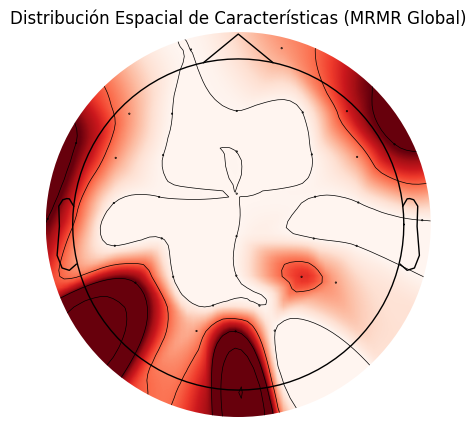


✅ PIPELINE DE INGENIERÍA DE CARACTERÍSTICAS COMPLETADO CON ÉXITO.


In [9]:
# ==============================================
# BLOQUE D: VISUALIZACIÓN TOPOGRÁFICA GLOBAL
# ==============================================
print("\n" + "="*60)
print("🧠 GENERANDO TOPOGRAFÍA DE CARACTERÍSTICAS GLOBALES")
print("="*60)

n_canales = len(info_maestra.ch_names)
importancias_espaciales = np.zeros(n_canales)

for feat in features_elegidas:
    canal = feat.split('_')[0]
    if canal in info_maestra.ch_names:
        idx = info_maestra.ch_names.index(canal)
        importancias_espaciales[idx] += 1

fig, ax = plt.subplots(figsize=(6, 5))
mne.viz.plot_topomap(importancias_espaciales, info_maestra, axes=ax, cmap='Reds', show=False, contours=4)
ax.set_title("Distribución Espacial de Características (MRMR Global)")
plt.savefig(os.path.join(config.ruta_output, "Topografia_MRMR_Global.png"), dpi=300, bbox_inches='tight')
plt.show()

print("\n✅ PIPELINE DE INGENIERÍA DE CARACTERÍSTICAS COMPLETADO CON ÉXITO.")

# **Auditoría Fisiológica Intersujeto y Métrica de Calidad de Señal**

Para comprender la variabilidad en el rendimiento de la decodificación posterior (fenómeno de BCI Illiteracy), se implementó una auditoría fisiológica sobre los datos crudos durante la fase de ingeniería de características. Esta evaluación busca aislar la "calidad biológica" de la señal de las capacidades algorítmicas de la red neuronal (Garbage In, Garbage Out).

Se diseñó un pipeline automatizado que extrae tres biomarcadores críticos por cada sujeto, calculados sobre el promedio de los ensayos (Potenciales Evocados - ERPs):

1.   **Amplitud del Componente N170 ($\mu V$):** Extraído como el pico mínimo entre los 140ms y 200ms en las derivaciones occipito-temporales (O1, O2, PO1, PO2, T5, T6). Este componente refleja el procesamiento estructural temprano de formas complejas. Una amplitud severamente atenuada indica deficiencias en el procesamiento visual de bajo nivel.
2.   **Amplitud del Componente P300 ($\mu V$):** Extraído como el pico máximo entre los 250ms y 450ms en las derivaciones parietales (Pz, P3, P4). Actúa como un marcador de atención sostenida y actualización de la memoria de trabajo.
3. **Relación Señal-Ruido ($SNR_{dB}$):** Calculada comparando la Raíz Cuadrada Media (RMS) de la ventana de activación visual (0.0s a 0.5s) contra la RMS de la ventana de línea base pre-estímulo (-0.1s a 0.0s). Se expresa en decibelios (dB) mediante la ecuación: $SNR_{dB} = 20 \cdot \log_{10}(RMS_{signal} / RMS_{baseline})$.

La tabulación de estas métricas permite establecer un ranking de "Integridad Fisiológica" por participante. Esta base de datos biológica servirá como variable independiente para ser correlacionada posteriormente con las métricas de pérdida semántica de las arquitecturas generativas (GAN-CLIP), permitiendo evaluar si las fallas en la reconstrucción topográfica de ciertos sujetos obedecen a deficiencias intrínsecas en la evocación de sus ERPs o a fluctuaciones en la impedancia durante la adquisición.


🔬 BLOQUE E: AUDITORÍA FISIOLÓGICA Y CALIDAD DE SEÑAL (ERPs y SNR)
⏳ Evaluando calidad de señal fisiológica para 21 sujetos...
Not setting metadata
237 matching events found
No baseline correction applied


/tmp/ipykernel_664/2187680283.py:28: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  ep_sujeto = mne.concatenate_epochs(epochs_list)


Not setting metadata
232 matching events found
No baseline correction applied


/tmp/ipykernel_664/2187680283.py:28: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  ep_sujeto = mne.concatenate_epochs(epochs_list)


Not setting metadata
236 matching events found
No baseline correction applied


/tmp/ipykernel_664/2187680283.py:28: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  ep_sujeto = mne.concatenate_epochs(epochs_list)


... (33 outputs left out)

/tmp/ipykernel_664/2187680283.py:28: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  ep_sujeto = mne.concatenate_epochs(epochs_list)


Not setting metadata
117 matching events found
No baseline correction applied


/tmp/ipykernel_664/2187680283.py:28: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  ep_sujeto = mne.concatenate_epochs(epochs_list)


✅ Base de datos fisiológica guardada en: /content/drive/Othercomputers/Mi portátil/Doctorado/VISUAL_DECODING/Neuroscan_Data/Procesado/05_Resultados_FeatureEngine/Auditoria_Fisiologica_Sujetos.csv


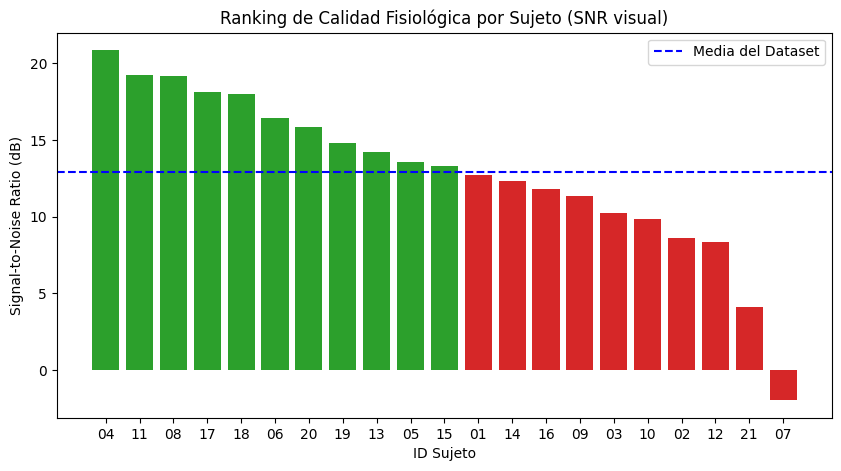


🏆 Mejor Sujeto Fisiológico (04): SNR = 20.85 dB, P300 = 9.05 µV
⚠️ Peor Sujeto Fisiológico (07): SNR = -1.96 dB, P300 = 2.98 µV

✅ PIPELINE COMPLETO DE INGENIERÍA DE CARACTERÍSTICAS FINALIZADO.


In [10]:
# ==============================================
# BLOQUE E: AUDITORÍA FISIOLÓGICA INTERSUJETOS (CALIDAD DE SEÑAL)
# ==============================================
print("\n" + "="*60)
print("🔬 BLOQUE E: AUDITORÍA FISIOLÓGICA Y CALIDAD DE SEÑAL (ERPs y SNR)")
print("="*60)

resultados_fisio = []

# Extraer lista única de sujetos a partir de la variable 'grupos' ya existente
sujetos_audit = np.unique(grupos)
print(f"⏳ Evaluando calidad de señal fisiológica para {len(sujetos_audit)} sujetos...")

for sujeto in sujetos_audit:
    # 1. Encontrar todos los archivos del sujeto actual
    archivos_sujeto = [f for f in archivos if os.path.basename(f).startswith(f"{sujeto}_")]
    if not archivos_sujeto:
        continue

    epochs_list = []
    for f in archivos_sujeto:
        ep = mne.read_epochs(f, preload=True, verbose=False)
        # NO se restringe a la lista de Robles: la auditoría usa TODOS los canales
        # de las épocas (data-driven). La lista de Robles solo se usa en el Bloque C.
        asegurar_baseline(ep, os.path.basename(f))
        epochs_list.append(ep)

    ep_sujeto = mne.concatenate_epochs(epochs_list)
    asegurar_baseline(ep_sujeto, f"sujeto {sujeto}")

    # 2. Calcular Potencial Evocado (Evoked)
    # Usamos una ventana desde la línea base (-0.1s) hasta la fase tardía (0.6s)
    evoked = ep_sujeto.copy().crop(tmin=-0.1, tmax=0.6).average()
    tiempos = evoked.times
    datos_evoked = evoked.data # Matriz: (canales, tiempos) en Voltios
    ch_names = evoked.ch_names

    # Índices topográficos clave (nombres modernos 10-20: T5/T6 clásicos = P7/P8)
    idx_occipitales = [ch_names.index(ch) for ch in ['PO1', 'PO2', 'O1', 'O2', 'P7', 'P8'] if ch in ch_names]
    idx_parietales = [ch_names.index(ch) for ch in ['Pz', 'P3', 'P4'] if ch in ch_names]

    # --- MÉTRICA 1: Amplitud N170 (Mínimo en occipitales entre 140-200ms) ---
    mask_n170 = (tiempos >= 0.14) & (tiempos <= 0.20)
    if len(idx_occipitales) > 0 and mask_n170.any():
        # Buscamos el pico más negativo (en microvoltios)
        val_n170 = np.min(datos_evoked[idx_occipitales][:, mask_n170]) * 1e6
    else:
        val_n170 = 0

    # --- MÉTRICA 2: Amplitud P300 (Máximo en parietales entre 250-450ms) ---
    mask_p300 = (tiempos >= 0.25) & (tiempos <= 0.45)
    if len(idx_parietales) > 0 and mask_p300.any():
        val_p300 = np.max(datos_evoked[idx_parietales][:, mask_p300]) * 1e6
    else:
        val_p300 = 0

    # --- MÉTRICA 3: Relación Señal-Ruido (SNR en dB) ---
    # Se calcula sobre TODOS los canales del evocado (montaje completo, data-driven),
    # no solo sobre la lista de Robles.
    # Nota: los valores de referencia del último re-corrido se calcularon solo con
    # los canales de Robles, así que la media puede cambiar ligeramente; son referencia.
    mask_baseline = (tiempos < 0.0)
    mask_signal = (tiempos >= 0.0) & (tiempos <= 0.5)

    rms_baseline = np.sqrt(np.mean(datos_evoked[:, mask_baseline]**2))
    rms_signal = np.sqrt(np.mean(datos_evoked[:, mask_signal]**2))

    # Evitar logaritmo de cero
    snr_db = 20 * np.log10(rms_signal / rms_baseline) if rms_baseline > 0 else 0

    resultados_fisio.append({
        'Sujeto': sujeto,
        'N170_Amplitud_uV': val_n170,
        'P300_Amplitud_uV': val_p300,
        'SNR_dB': snr_db
    })

    del ep_sujeto, evoked

# 3. Guardar Base de Datos Fisiológica
df_fisio = pd.DataFrame(resultados_fisio)
# Ordenar por SNR (de mayor a menor calidad biológica)
df_fisio = df_fisio.sort_values('SNR_dB', ascending=False)

ruta_csv_fisio = os.path.join(config.ruta_output, "Auditoria_Fisiologica_Sujetos.csv")
df_fisio.to_csv(ruta_csv_fisio, index=False)
print(f"✅ Base de datos fisiológica guardada en: {ruta_csv_fisio}")

# 4. Generar Gráfico de Ranking de Calidad Biológica
fig, ax = plt.subplots(figsize=(10, 5))
sujetos_ordenados = df_fisio['Sujeto'].values
snr_valores = df_fisio['SNR_dB'].values

colores = ['#2ca02c' if snr > np.mean(snr_valores) else '#d62728' for snr in snr_valores]
barras = ax.bar(sujetos_ordenados, snr_valores, color=colores)

ax.set_title("Ranking de Calidad Fisiológica por Sujeto (SNR visual)")
ax.set_ylabel("Signal-to-Noise Ratio (dB)")
ax.set_xlabel("ID Sujeto")
ax.axhline(y=np.mean(snr_valores), color='blue', linestyle='--', label='Media del Dataset')
ax.legend()

ruta_grafico_fisio = os.path.join(config.ruta_output, "Ranking_Fisiologico_SNR.png")
plt.savefig(ruta_grafico_fisio, dpi=300, bbox_inches='tight')
plt.show()

# 5. Reporte en consola
mejor_sujeto = df_fisio.iloc[0]
peor_sujeto = df_fisio.iloc[-1]
print(f"\n🏆 Mejor Sujeto Fisiológico ({mejor_sujeto['Sujeto']}): SNR = {mejor_sujeto['SNR_dB']:.2f} dB, P300 = {mejor_sujeto['P300_Amplitud_uV']:.2f} µV")
print(f"⚠️ Peor Sujeto Fisiológico ({peor_sujeto['Sujeto']}): SNR = {peor_sujeto['SNR_dB']:.2f} dB, P300 = {peor_sujeto['P300_Amplitud_uV']:.2f} µV")
print("\n✅ PIPELINE COMPLETO DE INGENIERÍA DE CARACTERÍSTICAS FINALIZADO.")